<a href="https://colab.research.google.com/github/Adheeshana/FIVORA/blob/Fabric-Defect-Detection-Experiments/RTDETR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

shiranihansika_defect_dataset_path = kagglehub.dataset_download('shiranihansika/defect-dataset')
mgjsiriwardhana_best_pt_file_path = kagglehub.dataset_download('mgjsiriwardhana/best-pt-file')

print('Data source import complete.')


In [ ]:
!pip install -q -U albumentations kagglehub ultralytics

import kagglehub
import albumentations as A
import cv2
import glob
import random
import yaml
import os
import shutil

print("🧹 Cleaning up old files...")
for old_folder in ['/kaggle/working/yolo_dataset', '/kaggle/working/runs']:
    if os.path.exists(old_folder): shutil.rmtree(old_folder)

print("⏳ Downloading your custom Bounding Box dataset...")
dataset_path = kagglehub.dataset_download("shiranihansika/defect-dataset")

yolo_base = '/kaggle/working/yolo_dataset'
os.makedirs(yolo_base, exist_ok=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.7/77.7 kB 4.9 MB/s eta 0:00:00
🧹 Cleaning up old files...
⏳ Downloading your custom Bounding Box dataset...


In [ ]:
TARGET_PER_CLASS = 400

def clip_bbox(x_c, y_c, w, h):
    x_min = max(0.0001, min(0.9999, x_c - (w / 2.0)))
    x_max = max(0.0001, min(0.9999, x_c + (w / 2.0)))
    y_min = max(0.0001, min(0.9999, y_c - (h / 2.0)))
    y_max = max(0.0001, min(0.9999, y_c + (h / 2.0)))
    return x_min + ((x_max - x_min) / 2.0), y_min + ((y_max - y_min) / 2.0), max(0.001, x_max - x_min), max(0.001, y_max - y_min)

data_root = dataset_path
for root, dirs, files in os.walk(dataset_path):
    if 'train' in dirs and 'valid' in dirs:
        data_root = os.path.dirname(root)
        break

classes = sorted([d for d in os.listdir(data_root) if os.path.isdir(os.path.join(data_root, d)) and not d.startswith('.')])

transform = A.Compose([
    A.Resize(640, 640), A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2)
], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels']))

for category in classes:
    c_id = classes.index(category)
    img_dir = os.path.join(data_root, category, 'train', 'images')
    lbl_dir = os.path.join(data_root, category, 'train', 'labels')
    if not os.path.exists(img_dir): continue

    valid_image_data, current_count = [], 0
    for img_path in [f for f in glob.glob(os.path.join(img_dir, "*.*")) if f.lower().endswith(('.jpg', '.png'))]:
        img_name = os.path.basename(img_path)
        txt_name = os.path.splitext(img_name)[0] + '.txt'
        src_txt = os.path.join(lbl_dir, txt_name)
        dst_img = os.path.join(yolo_base, 'train', 'images', img_name)
        dst_txt = os.path.join(yolo_base, 'train', 'labels', txt_name)

        if os.path.exists(src_txt):
            os.makedirs(os.path.dirname(dst_img), exist_ok=True); os.makedirs(os.path.dirname(dst_txt), exist_ok=True)
            if not os.path.exists(dst_img): os.symlink(img_path, dst_img)
            boxes = []
            with open(src_txt, 'r') as f_in, open(dst_txt, 'w') as f_out:
                for line in f_in:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        x, y, w, h = clip_bbox(*map(float, parts[1:5]))
                        f_out.write(f"{c_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")
                        boxes.append([x, y, w, h])
        if boxes:
            valid_image_data.append({'img_path': img_path, 'boxes': boxes}); current_count += 1

    aug_index = 0
    while current_count < TARGET_PER_CLASS and valid_image_data:
        sample = random.choice(valid_image_data)
        image = cv2.imread(sample['img_path'])
        if image is None: continue
        try:
            augmented = transform(image=cv2.cvtColor(image, cv2.COLOR_BGR2RGB), bboxes=sample['boxes'], class_labels=[c_id]*len(sample['boxes']))
            if augmented['bboxes']:
                new_img_name = f"aug_{c_id}_{aug_index}.jpg"; new_txt_name = f"aug_{c_id}_{aug_index}.txt"
                cv2.imwrite(os.path.join(yolo_base, 'train', 'images', new_img_name), cv2.cvtColor(augmented['image'], cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 75])
                with open(os.path.join(yolo_base, 'train', 'labels', new_txt_name), 'w') as f_out:
                    for bbox in augmented['bboxes']:
                        x, y, w, h = clip_bbox(*bbox[:4])
                        f_out.write(f"{c_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")
                current_count += 1; aug_index += 1
        except Exception: pass

for category in classes:
    c_id = classes.index(category)
    for split in ['valid', 'test']:
        img_dir = os.path.join(data_root, category, split, 'images')
        lbl_dir = os.path.join(data_root, category, split, 'labels')
        if not os.path.exists(img_dir): continue
        for img_name in [f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.png'))]:
            src_img = os.path.join(img_dir, img_name)
            src_txt = os.path.join(lbl_dir, os.path.splitext(img_name)[0] + '.txt')
            dst_img = os.path.join(yolo_base, split, 'images', img_name)
            dst_txt = os.path.join(yolo_base, split, 'labels', os.path.splitext(img_name)[0] + '.txt')
            os.makedirs(os.path.dirname(dst_img), exist_ok=True); os.makedirs(os.path.dirname(dst_txt), exist_ok=True)
            if not os.path.exists(dst_img): os.symlink(src_img, dst_img)
            if os.path.exists(src_txt):
                with open(src_txt, 'r') as f_in, open(dst_txt, 'w') as f_out:
                    for line in f_in:
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            x, y, w, h = clip_bbox(*map(float, parts[1:5]))
                            f_out.write(f"{c_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

with open('/kaggle/working/data.yaml', 'w') as f:
    yaml.dump({'path': yolo_base, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': len(classes), 'names': classes}, f)
print("✅ Dataset Perfectly Prepared for your Bounding Boxes!")

✅ Dataset Perfectly Prepared for your Bounding Boxes!


In [ ]:
import os
from ultralytics import RTDETR

print("🚀 Cheicking training status for Auto-Resume (Transformer Model)...")

last_ckpt = '/kaggle/working/runs/fabric_transformer_run/weights/last.pt'

if os.path.exists(last_ckpt):
    print(f"🔄 Found saved checkpoint! Resuming from {last_ckpt}")
    model = RTDETR(last_ckpt)
    results = model.train(resume=True)
else:
    print("🌟 Starting fresh Hybrid Transformer (RT-DETR) Training...")
    # Loading the Large Transformer Model for maximum accuracy
    model = RTDETR('rtdetr-l.pt')

    results = model.train(
        data='/kaggle/working/data.yaml',
        epochs=80,
        patience=30,
        imgsz=640,
        batch=8,                     # 🔴 Batch 8 is critical to prevent Out of Memory on Transformers
        device=0,
        cache=True,

        project='/kaggle/working/runs',
        name='fabric_transformer_run',

        mosaic=1.0,
        mixup=0.2,
        degrees=10.0,
        hsv_v=0.3,
        close_mosaic=15,

        exist_ok=True
    )

print("\n🎉 Hybrid Transformer Training Phase Complete!")
print("✅ The best model is permanently saved as: /kaggle/working/runs/fabric_transformer_run/weights/best.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
🚀 Checking training status for Auto-Resume (Transformer Model)...
🌟 Starting fresh Hybrid Transformer (RT-DETR) Training...
Ultralytics 8.4.153 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynam

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


train: Scanning /kaggle/working/yolo_dataset/train/labels... 2699 images, 2 backgrounds, 104 corrupt: 100% ━━━━━━━━━━━━ 2803/2803 175.1it/s 16.0s.0ss
train: /kaggle/working/yolo_dataset/train/images/20260713_115938_jpg.rf.p3FzxtuBEGoVTvpn7yZi.jpg: ignoring corrupt image/label: [Errno 30] Read-only file system: '/kaggle/working/yolo_dataset/train/images/20260713_115938_jpg.rf.p3FzxtuBEGoVTvpn7yZi.jpg'
train: /kaggle/working/yolo_dataset/train/images/20260713_120044_jpg.rf.SRyVvtjTXXDmpA2LVjE2.jpg: ignoring corrupt image/label: [Errno 30] Read-only file system: '/kaggle/working/yolo_dataset/train/images/20260713_120044_jpg.rf.SRyVvtjTXXDmpA2LVjE2.jpg'
train: /kaggle/working/yolo_dataset/train/images/20260713_120056_jpg.rf.ZVdu6yWZrjpVstq4p2ea.jpg: ignoring corrupt image/label: [Errno 30] Read-only file system: '/kaggle/working/yolo_dataset/train/images/20260713_120056_jpg.rf.ZVdu6yWZrjpVstq4p2ea.jpg'
train: /kaggle/working/yolo_dataset/train/images/20260713_120110_jpg.rf.6UewsOh7KvwRXWr7

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/150       6.7G     0.8752      5.651     0.5437         12        640: 100% ━━━━━━━━━━━━ 338/338 1.7it/s 3:150.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 2.3it/s 15.9s0.3s
                   all        563        709      0.666      0.533       0.52       0.25

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


...

     73/150      7.14G     0.4552      0.509     0.2414          9        640: 100% ━━━━━━━━━━━━ 338/338 1.9it/s 2:600.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.1it/s 11.5s0.3s
                   all        563        709       0.82      0.788      0.796      0.408

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     74/150      7.14G     0.4235     0.5782       0.11         23        640: 0% ──────────── 0/338  0.5s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     74/150      7.14G     0.4598     0.5074     0.2385          8        640: 100% ━━━━━━━━━━━━ 338/338 1.9it/s 2:600.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.1it/s 11.5s0.3s
                   all        563        709      0.841      0.816      0.826      0.437

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     75/150      7.14G     0.4547      0.436     0.2947         20        640: 0% ──────────── 0/338  0.6s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     75/150      7.14G     0.4532     0.5147     0.2361         13        640: 100% ━━━━━━━━━━━━ 338/338 1.9it/s 2:600.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.1it/s 11.4s0.3s
                   all        563        709       0.82      0.846      0.843      0.447
EarlyStopping: Training stopped early as no improvement observed in last 30 epochs. Best results observed at epoch 45, best model saved as best.pt.
To update EarlyStopping(patience=30) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

75 epochs completed in 4.034 hours.
Optimizer stripped from /kaggle/working/runs/fabric_transformer_run/weights/last.pt, 66.2MB
Optimizer stripped from /kaggle/working/runs/fabric_transformer_run/weights/best.pt, 66.2MB

Validating /kaggle/working/runs/fabric_transformer_run/weights/best.pt...
Ultralytics 8.4.153 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB

🏆 FINAL ACCURACY & EVALUATION (HYBRID TRANSFORMER) 🏆
⏳ Generating Confusion Matrix and Attention Graphs...
Ultralytics 8.4.153 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 31,998,125 parameters, 0 gradients, 105.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 34.5±10.5 MB/s, size: 7346.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/working/yolo_dataset/test/labels... 48 images, 0 backgrounds, 15 corrupt: 21% ━━╸───────── 63/293 48.4it/s 1.2s<4.8s

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


val: Scanning /kaggle/working/yolo_dataset/test/labels... 278 images, 0 backgrounds, 15 corrupt: 100% ━━━━━━━━━━━━ 293/293 98.1it/s 3.0s<0.0s
val: /kaggle/working/yolo_dataset/test/images/20260713_121359_jpg.rf.oL6cN2IPM7O5nQCd2GF2.jpg: ignoring corrupt image/label: [Errno 30] Read-only file system: '/kaggle/working/yolo_dataset/test/images/20260713_121359_jpg.rf.oL6cN2IPM7O5nQCd2GF2.jpg'
val: /kaggle/working/yolo_dataset/test/images/20260713_153754_jpg.rf.VB9W87E8Mq4xK9hgeybi.jpg: ignoring corrupt image/label: [Errno 30] Read-only file system: '/kaggle/working/yolo_dataset/test/images/20260713_153754_jpg.rf.VB9W87E8Mq4xK9hgeybi.jpg'
val: /kaggle/working/yolo_dataset/test/images/20260713_153801_jpg.rf.oH2fchf2YTqoO35ccum3.jpg: ignoring corrupt image/label: [Errno 30] Read-only file system: '/kaggle/working/yolo_dataset/test/images/20260713_153801_jpg.rf.oH2fchf2YTqoO35ccum3.jpg'
val: /kaggle/working/yolo_dataset/test/images/20260713_153804_jpg.rf.2XddacnkR1fmB7rJ9q1D.jpg: ignoring corr

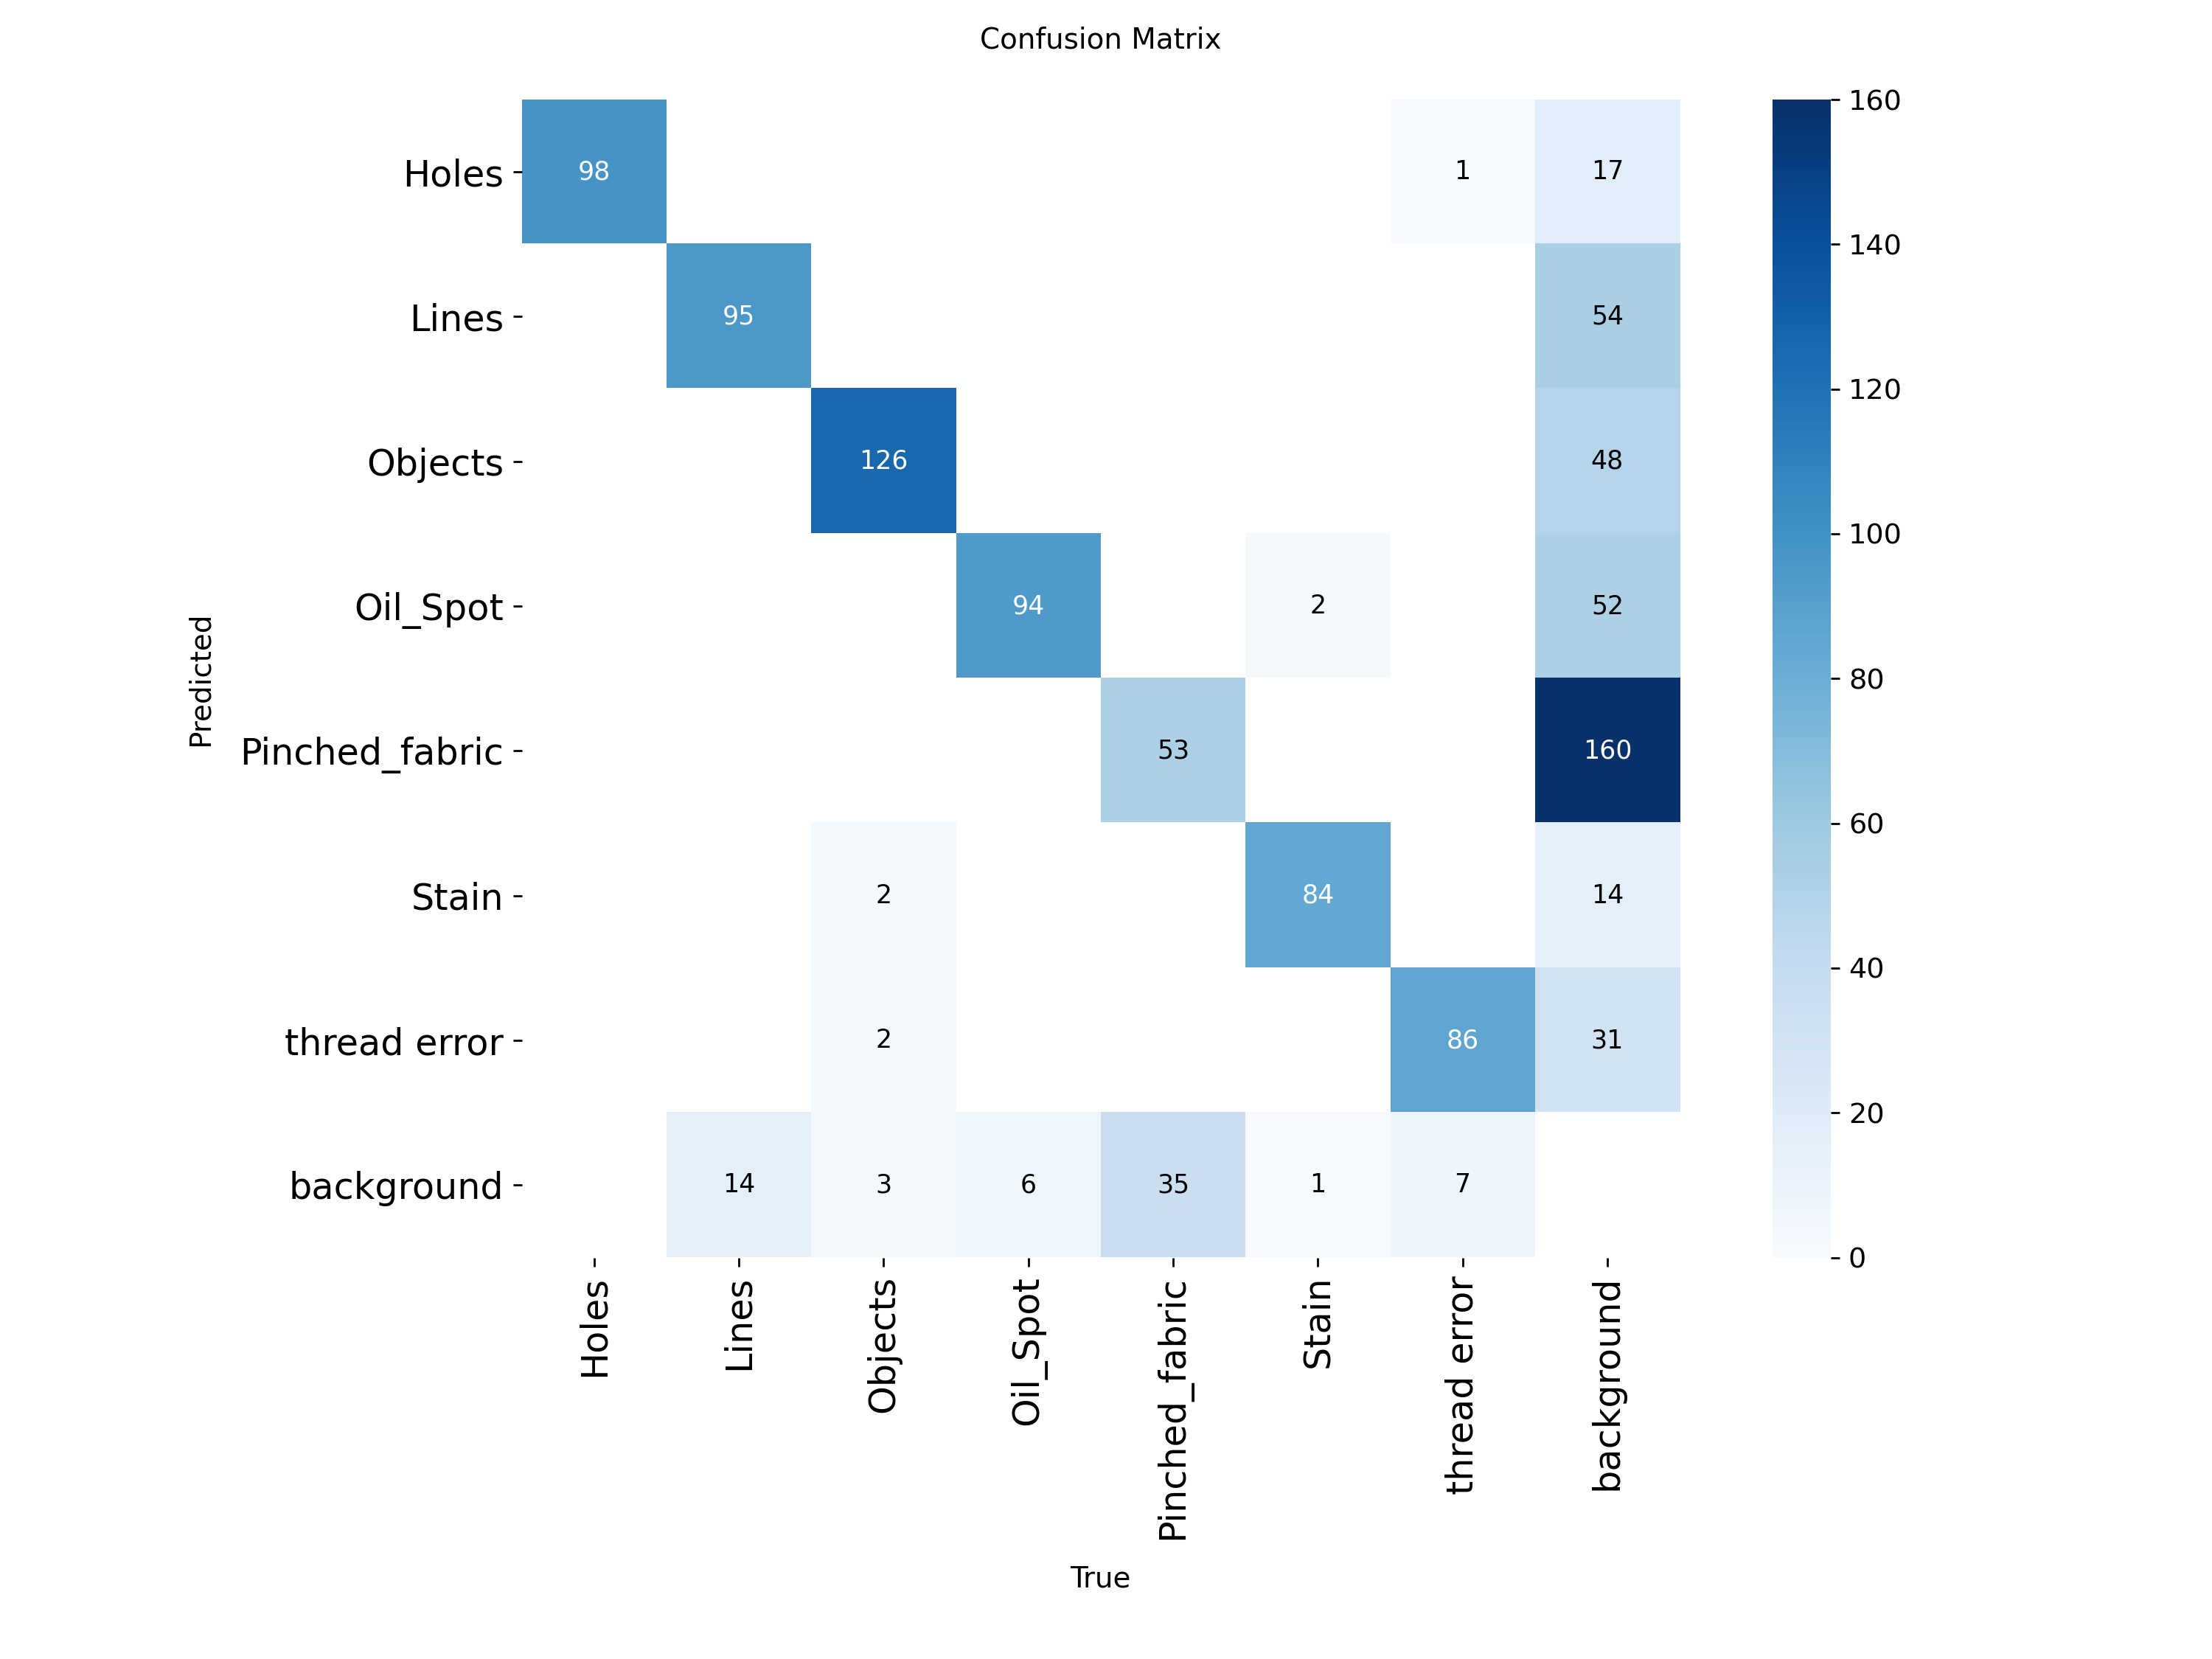

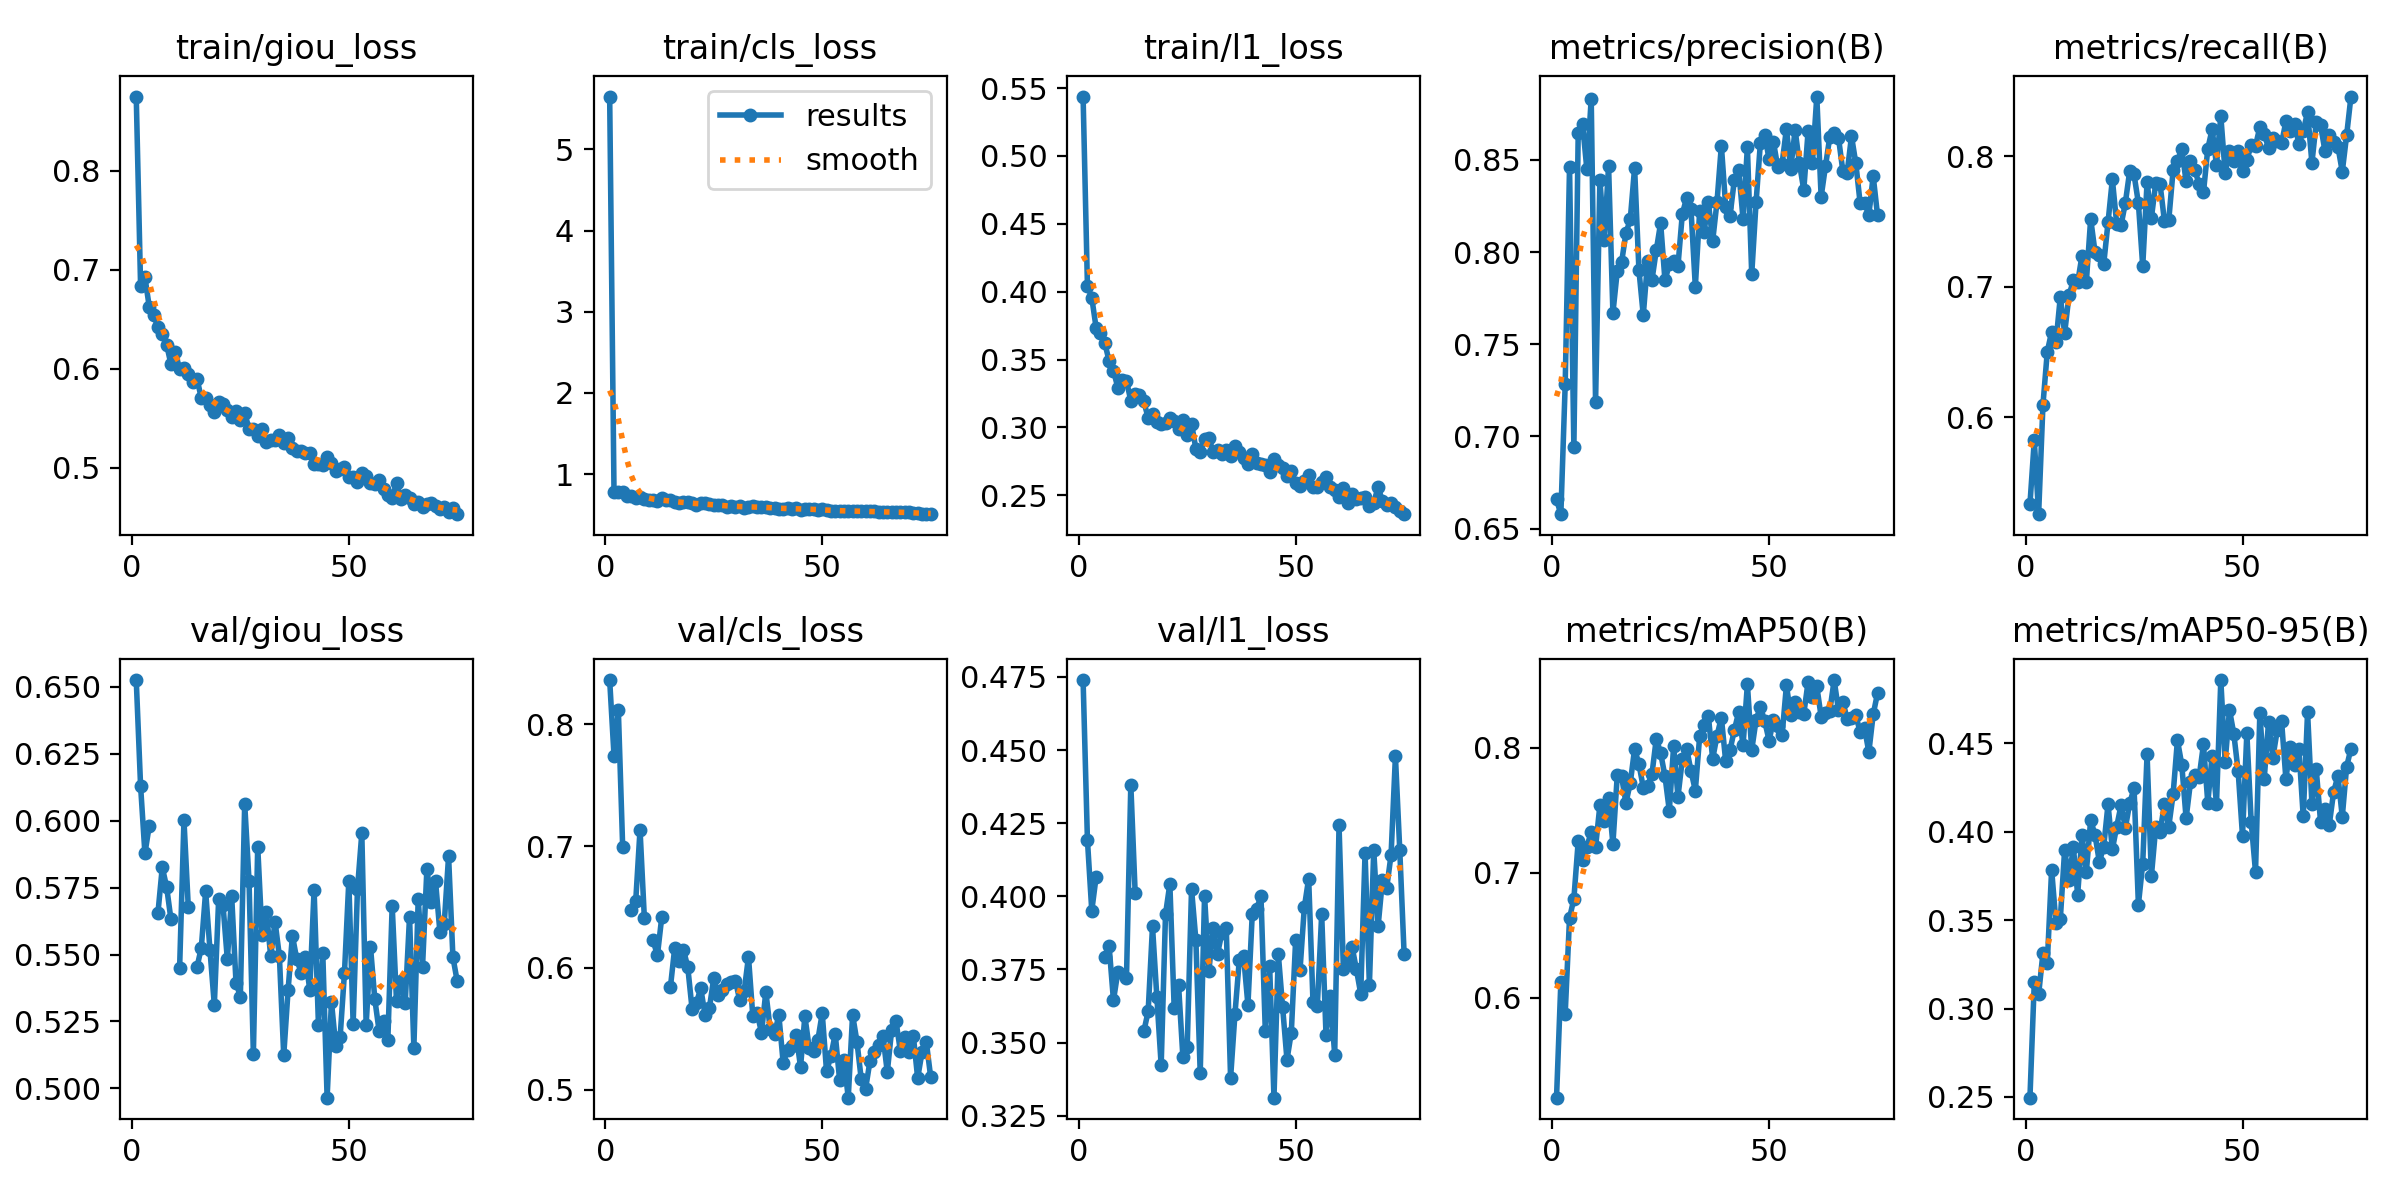


📦 Download your complete Hybrid Transformer project (Model + Graphs) below:


/kaggle/working/Final_Project_Transformer_Results.zip

In [ ]:
import shutil
import os
from IPython.display import FileLink, display, Image
from ultralytics import RTDETR

run_dir = '/kaggle/working/runs/fabric_transformer_run'
best_model = f"{run_dir}/weights/best.pt"

if os.path.exists(best_model):
    print("🏆 FINAL ACCURACY & EVALUATION (HYBRID TRANSFORMER) 🏆")

    # Load the trained Transformer model
    model = RTDETR(best_model)
    print("⏳ Generating Confusion Matrix and Attention Graphs...")

    metrics = model.val(data='/kaggle/working/data.yaml', split='test')
    print(f"\n🎯 Final Accuracy (mAP@50): {metrics.box.map50 * 100:.2f}%\n")

    cm_path = os.path.join(run_dir, 'confusion_matrix.png')
    results_path = os.path.join(run_dir, 'results.png')

    print("📊 Visualizations (Confusion Matrix & Training Results):\n")
    if os.path.exists(cm_path): display(Image(filename=cm_path, width=600))
    if os.path.exists(results_path): display(Image(filename=results_path, width=800))

    shutil.make_archive('/kaggle/working/Final_Project_Transformer_Results', 'zip', run_dir)
    print("\n📦 Download your complete Hybrid Transformer project (Model + Graphs) below:")
    display(FileLink('Final_Project_Transformer_Results.zip'))
else:
    print("❌ best.pt file not found. Training might have crashed or not completed.")


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Load the model
best_model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'
model = RTDETR(best_model_path)

# 2. Create UI widgets
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click "Predict"
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")

        # Handle different versions of ipywidgets file data
        try:
            # For ipywidgets 8.0+
            content = uploader.value[0].content
        except:
            # For older ipywidgets versions
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert the uploaded file bytes into an OpenCV image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Run inference
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert BGR to RGB for displaying correctly
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Show the image
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
from IPython.display import FileLink

# The exact path to your trained model file
model_path = '/kaggle/working/runs/fabric_transformer_run/weights/best.pt'

# Create and display a clickable download link
display(FileLink(model_path))

/kaggle/working/runs/fabric_transformer_run/weights/best.pt

In [ ]:
import os
from IPython.display import FileLink, display

print("🔍 Searching for .pt files in Kaggle...")
found_files = []

# /kaggle/working/ ෆෝල්ඩරය ඇතුළේ තියෙන හැම ෆයිල් එකක්ම හොයනවා
for root, dirs, files in os.walk('/kaggle/working/'):
    for file in files:
        if file.endswith(".pt"): # .pt ෆයිල් පමණක් තෝරාගැනීම
            full_path = os.path.join(root, file)
            found_files.append(full_path)

if len(found_files) == 0:
    print("❌ No .pt files found! (File එක මැකිලා හරි, හරියට Save වෙලා නෑ හරි)")
else:
    print("✅ Found these files! Click on the link to download:")
    for file_path in found_files:
        print(f"Path: {file_path}")
        display(FileLink(file_path))

🔍 Searching for .pt files in Kaggle...
✅ Found these files! Click on the link to download:
Path: /kaggle/working/rtdetr-l.pt


/kaggle/working/rtdetr-l.pt

Path: /kaggle/working/weights/yolo26n.pt


/kaggle/working/weights/yolo26n.pt

Path: /kaggle/working/runs/fabric_transformer_run/weights/last.pt


/kaggle/working/runs/fabric_transformer_run/weights/last.pt

Path: /kaggle/working/runs/fabric_transformer_run/weights/best.pt


/kaggle/working/runs/fabric_transformer_run/weights/best.pt

In [ ]:
!pip install -q -U ultralytics

In [ ]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Setup the Model Path
model_path = '/kaggle/input/datasets/mgjsiriwardhana/best-pt-file'

# Smart check: If the path is a folder, find the .pt file inside it automatically
if os.path.isdir(model_path):
    for file in os.listdir(model_path):
        if file.endswith('.pt'):
            model_path = os.path.join(model_path, file)
            break

print(f"⏳ Loading model from: {model_path}")
model = RTDETR(model_path)
print("✅ Model loaded successfully!")

# 2. Create Upload and Predict Buttons
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("\n1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click predict
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")
        try:
            # For newer ipywidgets in Kaggle
            content = uploader.value[0].content
        except:
            # For older ipywidgets
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert uploaded data to an image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Make the prediction
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert colors for Matplotlib
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Display the output
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

⏳ Loading model from: /kaggle/input/datasets/mgjsiriwardhana/best-pt-file/best.pt
✅ Model loaded successfully!

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Setup the Model Path
model_path = '/kaggle/input/datasets/mgjsiriwardhana/best-pt-file'

# Smart check: If the path is a folder, find the .pt file inside it automatically
if os.path.isdir(model_path):
    for file in os.listdir(model_path):
        if file.endswith('.pt'):
            model_path = os.path.join(model_path, file)
            break

print(f"⏳ Loading model from: {model_path}")
model = RTDETR(model_path)
print("✅ Model loaded successfully!")

# 2. Create Upload and Predict Buttons
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("\n1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click predict
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")
        try:
            # For newer ipywidgets in Kaggle
            content = uploader.value[0].content
        except:
            # For older ipywidgets
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert uploaded data to an image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Make the prediction
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert colors for Matplotlib
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Display the output
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

⏳ Loading model from: /kaggle/input/datasets/mgjsiriwardhana/best-pt-file/best.pt
✅ Model loaded successfully!

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Setup the Model Path
model_path = '/kaggle/input/datasets/mgjsiriwardhana/best-pt-file'

# Smart check: If the path is a folder, find the .pt file inside it automatically
if os.path.isdir(model_path):
    for file in os.listdir(model_path):
        if file.endswith('.pt'):
            model_path = os.path.join(model_path, file)
            break

print(f"⏳ Loading model from: {model_path}")
model = RTDETR(model_path)
print("✅ Model loaded successfully!")

# 2. Create Upload and Predict Buttons
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("\n1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click predict
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")
        try:
            # For newer ipywidgets in Kaggle
            content = uploader.value[0].content
        except:
            # For older ipywidgets
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert uploaded data to an image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Make the prediction
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert colors for Matplotlib
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Display the output
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

⏳ Loading model from: /kaggle/input/datasets/mgjsiriwardhana/best-pt-file/best.pt
✅ Model loaded successfully!

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Setup the Model Path
model_path = '/kaggle/input/datasets/mgjsiriwardhana/best-pt-file'

# Smart check: If the path is a folder, find the .pt file inside it automatically
if os.path.isdir(model_path):
    for file in os.listdir(model_path):
        if file.endswith('.pt'):
            model_path = os.path.join(model_path, file)
            break

print(f"⏳ Loading model from: {model_path}")
model = RTDETR(model_path)
print("✅ Model loaded successfully!")

# 2. Create Upload and Predict Buttons
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("\n1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click predict
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")
        try:
            # For newer ipywidgets in Kaggle
            content = uploader.value[0].content
        except:
            # For older ipywidgets
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert uploaded data to an image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Make the prediction
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert colors for Matplotlib
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Display the output
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

⏳ Loading model from: /kaggle/input/datasets/mgjsiriwardhana/best-pt-file/best.pt
✅ Model loaded successfully!

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Setup the Model Path
model_path = '/kaggle/input/datasets/mgjsiriwardhana/best-pt-file'

# Smart check: If the path is a folder, find the .pt file inside it automatically
if os.path.isdir(model_path):
    for file in os.listdir(model_path):
        if file.endswith('.pt'):
            model_path = os.path.join(model_path, file)
            break

print(f"⏳ Loading model from: {model_path}")
model = RTDETR(model_path)
print("✅ Model loaded successfully!")

# 2. Create Upload and Predict Buttons
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("\n1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click predict
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")
        try:
            # For newer ipywidgets in Kaggle
            content = uploader.value[0].content
        except:
            # For older ipywidgets
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert uploaded data to an image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Make the prediction
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert colors for Matplotlib
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Display the output
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

⏳ Loading model from: /kaggle/input/datasets/mgjsiriwardhana/best-pt-file/best.pt
✅ Model loaded successfully!

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()

In [ ]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

# 1. Setup the Model Path
model_path = '/kaggle/input/datasets/mgjsiriwardhana/best-pt-file'

# Smart check: If the path is a folder, find the .pt file inside it automatically
if os.path.isdir(model_path):
    for file in os.listdir(model_path):
        if file.endswith('.pt'):
            model_path = os.path.join(model_path, file)
            break

print(f"⏳ Loading model from: {model_path}")
model = RTDETR(model_path)
print("✅ Model loaded successfully!")

# 2. Create Upload and Predict Buttons
uploader = widgets.FileUpload(accept='image/*', multiple=False)
predict_button = widgets.Button(description="Predict", button_style='success')
output = widgets.Output()

print("\n1️⃣ Click 'Upload' to select an image from your computer.")
print("2️⃣ Click 'Predict' to see the results.")
display(uploader, predict_button, output)

# 3. Define what happens when you click predict
def on_button_clicked(b):
    with output:
        clear_output()
        if not uploader.value:
            print("❌ Please upload an image first!")
            return

        print("⏳ Processing image...")
        try:
            # For newer ipywidgets in Kaggle
            content = uploader.value[0].content
        except:
            # For older ipywidgets
            filename = list(uploader.value.keys())[0]
            content = uploader.value[filename]['content']

        # Convert uploaded data to an image
        nparr = np.frombuffer(content, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        # Make the prediction
        results = model.predict(source=img, conf=0.25, save=False)
        annotated_image = results[0].plot()

        # Convert colors for Matplotlib
        annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        # Display the output
        plt.figure(figsize=(10, 10))
        plt.imshow(annotated_image_rgb)
        plt.axis('off')
        plt.title("Defect Detection Results", fontsize=16)
        plt.show()

predict_button.on_click(on_button_clicked)

⏳ Loading model from: /kaggle/input/datasets/mgjsiriwardhana/best-pt-file/best.pt
✅ Model loaded successfully!

1️⃣ Click 'Upload' to select an image from your computer.
2️⃣ Click 'Predict' to see the results.


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()